# Investigate a Dataset No Show Appointment

## Table of Contents
<ul>
<li><a href="#intro">Introduction</a></li>
<li><a href="#wrangling">Data Wrangling</a></li>
<li><a href="#eda">Exploratory Data Analysis</a></li>
<li><a href="#conclusions">Conclusions</a></li>
</ul>

<a id='intro'></a>
## Introduction

1. What is the percentage of those who attended the appoinment vs to those who did not attend?
2. What are the most important characteristics and effect them to the patient that showed up to their appointment or he did not show up?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

<a id="wrangling"></a>
## Data Wrangling

> In this section, I will load in the data, check for cleanliness, and then trim and clean dataset for anaylis.

### General Properties
> Loading the data and printing out a few lines in data frame

In [2]:
df = pd.read_csv("./data/noshowappointments-kagglev2-may-2016.csv")
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


> Viewing dimension of dataset

In [3]:
df.shape

(110527, 14)

We have 110527 rows and 14 columns
 
>Summary statistics of data

In [4]:
df.describe()

,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


> Checking the info of the data types and null values

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  str    
 3   ScheduledDay    110527 non-null  str    
 4   AppointmentDay  110527 non-null  str    
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  str    
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  str    
dtypes: float64(1), int64(8), str(5)
memory usage: 11.8 MB


We do not have any null values in this dataset

> Checking if there are duplicated rows in the data

In [7]:
df.duplicated().sum()

np.int64(0)

We do not have any duplicated rows

## Data Cleaning

> Includes removing any data harmful for the analysis, drop features that are not relevant to our questions and rename column labels

> Dropping columns that are not relevant to our questions

In [8]:
df.drop(['PatientId', 'Neighbourhood', 'AppointmentID','Scholarship','Hipertension', 'Diabetes', 'Alcoholism','Handcap', 'ScheduledDay', 'AppointmentDay'], axis=1, inplace=True)

> Showing the columns and some of rows in the dataframe to confirm changes

In [9]:
df.head()

,Gender,Age,SMS_received,No-show
0,F,62,0,No
1,M,56,0,No
2,F,62,0,No
3,F,8,0,No
4,F,56,0,No


> Rename all column labels to be much easier to work witht them

In [10]:
df.rename(columns={ 'Gender': 'gender', 'Age': 'age', 'SMS_received': 'sms_received', 'No-show': 'no_show'}, inplace=True)

In [11]:
df.head()

,gender,age,sms_received,no_show
0,F,62,0,No
1,M,56,0,No
2,F,62,0,No
3,F,8,0,No
4,F,56,0,No


> Converting no_show values to boolean (0 and 1) instead of ('Yes' and 'No'd)

In [19]:
df.no_show.replace({'No' : 0, 'Yes' : 1}, inplace=True)

C:\Users\giapnguyen\AppData\Local\Temp\ipykernel_21628\3866177545.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df.no_show.replace({'No' : 0, 'Yes' : 1}, inplace=True)


0         0
1         0
2         0
3         0
4         0
         ..
110522    0
110523    0
110524    0
110525    0
110526    0
Name: no_show, Length: 110527, dtype: object

> Converting 'no_show' column to int

In [24]:
df['no_show'] = df['no_show'].astype(int)

In [25]:
df.head()

,gender,age,sms_received,no_show
0,F,62,0,0
1,M,56,0,0
2,F,62,0,0
3,F,8,0,0
4,F,56,0,0


> Check if there is any error value in range (value = zero or negative)

In [26]:
df[df['age'] <= 0]

,gender,age,sms_received,no_show
59,F,0,0,0
63,M,0,0,0
64,M,0,1,0
65,M,0,0,0
67,F,0,0,0
...,...,...,...,...
110345,F,0,0,0
110346,M,0,0,0
110454,F,0,0,0
110460,F,0,0,0


> Creating new dataframe from the old dataframe without the rows that have error values in age and confirming the changes

In [27]:
data_f = df[(df['age']>0)]
data_f.head()

,gender,age,sms_received,no_show
0,F,62,0,0
1,M,56,0,0
2,F,62,0,0
3,F,8,0,0
4,F,56,0,0


> Checking the info of the data types and null values in the new dataframe 'data_f'

In [28]:
data_f.info()

<class 'pandas.DataFrame'>
Index: 106987 entries, 0 to 110526
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   gender        106987 non-null  str  
 1   age           106987 non-null  int64
 2   sms_received  106987 non-null  int64
 3   no_show       106987 non-null  int64
dtypes: int64(3), str(1)
memory usage: 4.1 MB


> Viewing the dimensions of datase

In [29]:
data_f.shape

(106987, 4)

<a id="eda"></a>
## Exploratory Data Analysis

### Research Question 1: What is percentage of those who attended the appoinment vs to those who did not attend?

> Creating a pipe chart to compare the percentage of those who attended the appointment vs to those who did not attend

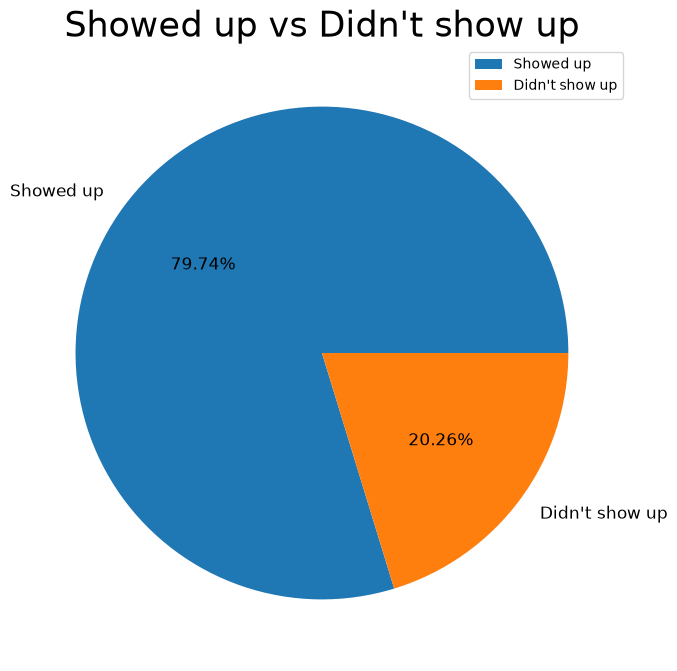

In [32]:
show_counts = data_f.no_show.value_counts()
labels = ["Showed up", "Didn't show up"]
plt.title("Showed up vs Didn't show up", size=25)
show_counts.plot.pie(figsize=(8, 8), labels=labels, autopct='%.2f%%', fontsize=12)
plt.legend()

### Research Question 2: What are the most important characteristics (age, gender, and SMS received) and effect them to the patient that showed up to their appointment or he did not show up?

> Create masks for rows where patients showed up and rows where they did not show up to make them easier to grab

In [35]:
showed = data_f.no_show == 0
not_showed = data_f.no_show == 1

> Calculating the mean of patient's ages that did show up

In [34]:
data_f.age[showed].mean()

np.float64(39.07518726482)

> Calculating the mean of patient's ages that did not show up

In [36]:
data_f.age[not_showed].mean()

np.float64(35.329151291512915)

> We notice that patients who came to their appointments they are older than they did not come

> Create histogram to study the relationship better and compare them in visual

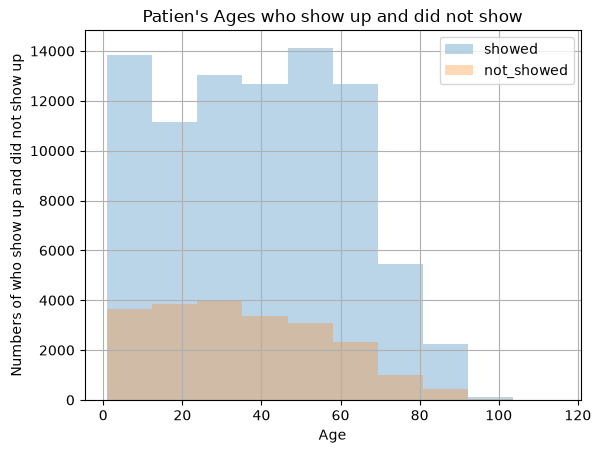

In [40]:
plt.title("Patien's Ages who show up and did not show")
plt.xlabel("Age")
plt.ylabel("Numbers of who show up and did not show up")
data_f.age[showed].hist(alpha=0.3, label='showed'), data_f.age[not_showed].hist(alpha=0.3, label='not_showed')
plt.legend()

> Creating histogram to study the relationship between sms receives and who came to their appointments and they did not come

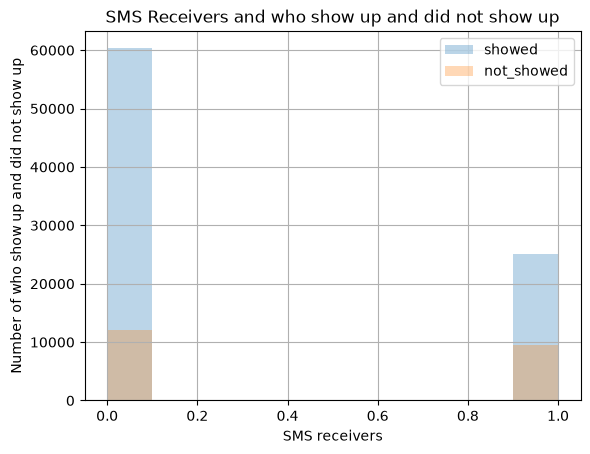

In [46]:
plt.title("SMS Receivers and who show up and did not show up")
plt.xlabel('SMS receivers')
plt.ylabel("Number of who show up and did not show up")
data_f.sms_received[showed].hist(alpha=0.3, label='showed'), data_f.sms_received[not_showed].hist(alpha=0.3, label='not_showed')
plt.legend()


<li>SMS receivers = 0 It means the patient who did not receive SMS</li>
<li>SMS receivers = 1 It means the patient who did receive SMS</li>

> Creating a pie chart to compare the percentage of those who received SMS vs to those who did not receive

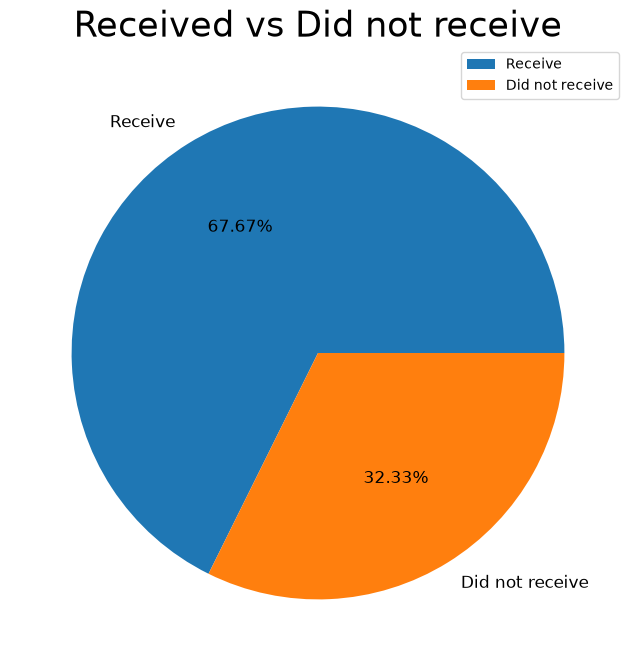

In [42]:
received_counts = data_f.sms_received.value_counts()
labels = ["Receive", "Did not receive"]
plt.title("Received vs Did not receive", size=25)
received_counts.plot.pie(figsize=(8, 8), labels=labels, autopct='%.2f%%', fontsize=12)
plt.legend()

We notice there are 67.67% of patients received SMS to their appointments and 32.33% of them did not receive SMS

> Calculating the mean of patient's gender that showed up and did not show up by using groupby() function

In [43]:
data_f.groupby('gender').no_show.mean()

gender
F    0.203585
M    0.200846
Name: no_show, dtype: float64

We notice there is not different in average between males and females

> Creating a bar chart to study the relationship better and compare them in visual

<Axes: title={'center': 'Females and Males who showed up and did not'}, xlabel='gender', ylabel='The average of females and males'>

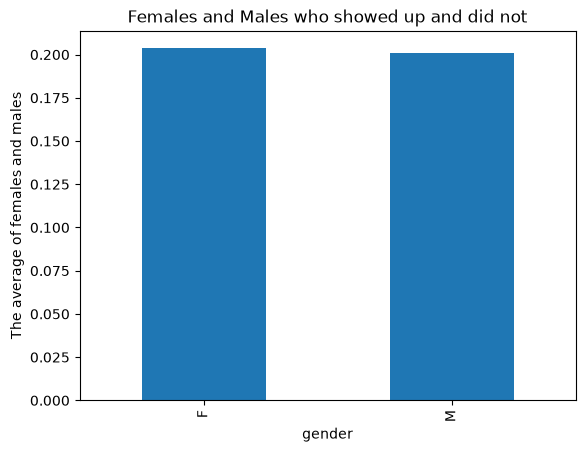

In [47]:
plt.title("Females and Males who showed up and did not")
plt.ylabel('The average of females and males')
data_f.groupby('gender')['no_show'].mean().plot(kind='bar')

## Conclusions

<li>We notice that patients who came to their appointments they are older than the ones who did not come</li>
<li>The SMS did not appear increasing hand to hand with the number of patients who showed up</li>
<li>The average no-show rates for males and females are similar. Therefore, gender appears to have little association with whether a patient attends their appointment.</li>
<li>Age seems to be the main effective feature that is important in this study</li> 
> <li>We notice there are 79.74% of patients came to their appoinments and 20.26% of them did not come</li>


## Limitation

<li>In addition to that, the value of age in this data, were lacking informations and numbers, missing features concerning the employee or unemployee in this data, that could be useful for its analysis and helpful to our predions and conclusions</li>
<li>The range of this analysis is limited for 100k medical appointments in Brazil, therefore the conclusions and findings do not representative sample, so as a matter of fact, we can not predict at any of this different regions, the possibility of the patient showing up or not for the appointment.</li>